# 04 - Inventory simulation

Story notebook for Q3. The dataset has **no inventory data**, so this simulates a periodic-review order-up-to policy on top of the Phase 3 forecast. All logic is in `src/sca/simulation.py` and `src/sca/simulation_report.py`. Run `python -m sca forecast` first.

In [1]:
import os
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(root)

from sca import simulation as sim
from sca import simulation_report as sr
from sca.config import load_config, run_paths
from sca.ingest import read_processed

cfg = load_config()
paths = run_paths(cfg)
tables = read_processed(paths.processed_dir)
forecast, residuals, champion = sr.load_phase3(paths.processed_dir)
print(f"Phase 3 champion: {champion}; {forecast['category'].nunique() - 1} categories")

Phase 3 champion: sarima; 9 categories


## Assumptions

All of these are in `config.yaml` and are assumptions, not facts about the business.

In [2]:
s = cfg.simulation
pd.Series(
    {
        "policy": "periodic review, order-up-to (R, S)",
        "review period (weeks)": s.review_period_weeks,
        "supplier lead time (weeks -> probability)": dict(zip(s.lead_time_weeks, s.lead_time_probs, strict=True)),
        "unit cost (% of list price)": s.unit_cost_proxy_pct_of_price,
        "holding cost (% of unit cost per week)": s.holding_cost_pct_per_week,
        "simulations x weeks": f"{s.n_sims:,} x {s.horizon_weeks}",
    },
    name="assumption",
).to_frame()

,assumption
policy,"periodic review, order-up-to (R, S)"
review period (weeks),1
supplier lead time (weeks -> probability),"{1: 0.3, 2: 0.5, 3: 0.2}"
unit cost (% of list price),0.6
holding cost (% of unit cost per week),0.005
simulations x weeks,"10,000 x 52"


## Why the textbook formula is not enough

The textbook safety stock `z * sigma * sqrt(R + L)` assumes a fixed lead time. Here the supplier lead time varies, which adds `mu * sd(L)` to the uncertainty.

In [3]:
m = sim.build_demand_models(forecast, residuals, sr.unit_prices(tables), s.horizon_weeks)[0]
print(f"{m.category}: mean demand {m.mu:,.0f}/wk, forecast-error sd {m.sigma:.1f}")
print(f"lead time: mean {sim.mean_lead_time(s):.2f} wk, sd {sim.lead_time_sd(s):.2f} wk")
print(f"textbook sd over R+L: {m.sigma * (s.review_period_weeks + sim.mean_lead_time(s)) ** 0.5:.1f}   "
      f"lead-time-aware sd: {sim.lead_aware_sigma(m, s):.1f}")

Camping & Hiking: mean demand 92/wk, forecast-error sd 7.9
lead time: mean 1.90 wk, sd 0.70 wk
textbook sd over R+L: 13.5   lead-time-aware sd: 65.9


## Run the simulation

In [4]:
run = sr.run(cfg, tables, paths.processed_dir)
sr.write_outputs(run, paths)          # charts, tables and reports/simulation_results.md
print(f"{len(run.models)} categories, {len(run.results)} simulated policies in {run.seconds:.0f}s")
run.results[run.results['category'] == m.category][
    ['basis', 'z', 'safety_stock', 'p_any_stockout', 'cycle_service_level', 'fill_rate', 'holding_cost']
].round(3)

9 categories, 153 simulated policies in 3s


,basis,z,safety_stock,p_any_stockout,cycle_service_level,fill_rate,holding_cost
0,lead_time_aware,0.000,0,1.000,0.573,0.863,1685.566
1,lead_time_aware,0.250,16,1.000,0.715,0.898,2003.477
2,textbook,1.282,17,1.000,0.724,0.899,2027.458
3,textbook,1.645,22,1.000,0.770,0.908,2155.013
4,textbook,2.054,28,1.000,0.820,0.917,2325.057
5,textbook,2.326,31,1.000,0.840,0.921,2416.444
6,lead_time_aware,0.500,33,1.000,0.850,0.923,2479.433
7,lead_time_aware,0.750,49,0.999,0.888,0.940,3017.483
8,lead_time_aware,1.000,66,0.999,0.890,0.956,3608.912
9,lead_time_aware,1.250,82,0.999,0.894,0.972,4167.746


## Results

## Analytic baseline vs simulation

| Category | Mean demand / wk | Forecast-error sd | SS @90% | Simulated @90% | SS @95% | Simulated @95% | SS @98% | Simulated @98% | SS @99% | Simulated @99% |
|---|---|---|---|---|---|---|---|---|---|---|
| Camping & Hiking | 92 | 7.9 | 17 | 72.4% | 22 | 77.0% | 28 | 82.0% | 31 | 84.0% |
| Cardio Equipment | 250 | 30.2 | 66 | 82.6% | 85 | 85.3% | 106 | 87.4% | 120 | 88.2% |
| Cleats | 491 | 40.2 | 88 | 83.1% | 113 | 85.7% | 140 | 87.4% | 159 | 88.1% |
| Fishing | 116 | 11.1 | 24 | 76.5% | 31 | 80.7% | 39 | 84.2% | 44 | 85.8% |
| Indoor/Outdoor Games | 400 | 39.2 | 85 | 82.8% | 110 | 86.1% | 137 | 88.0% | 155 | 88.6% |
| Men's Footwear | 149 | 15.7 | 34 | 79.8% | 44 | 83.6% | 55 | 86.2% | 62 | 87.2% |
| Shop By Sport | 218 | 27.4 | 60 | 82.6% | 77 | 85.8% | 96 | 87.9% | 109 | 88.7% |
| Water Sports | 104 | 11.5 | 25 | 73.8% | 32 | 78.8% | 40 | 83.7% | 46 | 86.3% |
| Women's Apparel | 420 | 41.1 | 90 | 79.8% | 115 | 83.3% | 144 | 86.1% | 163 | 87.4% |

The textbook formula assumes a fixed lead time. With supplier lead times of 1 to 3 weeks (sd 0.70), the simulated cycle service level at the 95% setting averages **82.9%** across categories, below the 95% target. Lead-time variability makes up 94% of the variance of demand over the protection interval, which the formula ignores.

![Analytic vs simulated](figures/simulation_02_analytic_vs_simulated.png)

Stock needed to actually reach a simulated 95% cycle service level, versus the textbook figure:

| Category | Textbook SS | Simulated SS needed | Multiple of textbook |
|---|---|---|---|
| Camping & Hiking | 22 | 115 | 5.2x |
| Cardio Equipment | 85 | 273 | 3.2x |
| Cleats | 113 | 526 | 4.7x |
| Fishing | 31 | 145 | 4.7x |
| Indoor/Outdoor Games | 110 | 432 | 3.9x |
| Men's Footwear | 44 | 189 | 4.3x |
| Shop By Sport | 77 | 279 | 3.6x |
| Water Sports | 32 | 132 | 4.1x |
| Women's Apparel | 115 | 529 | 4.6x |



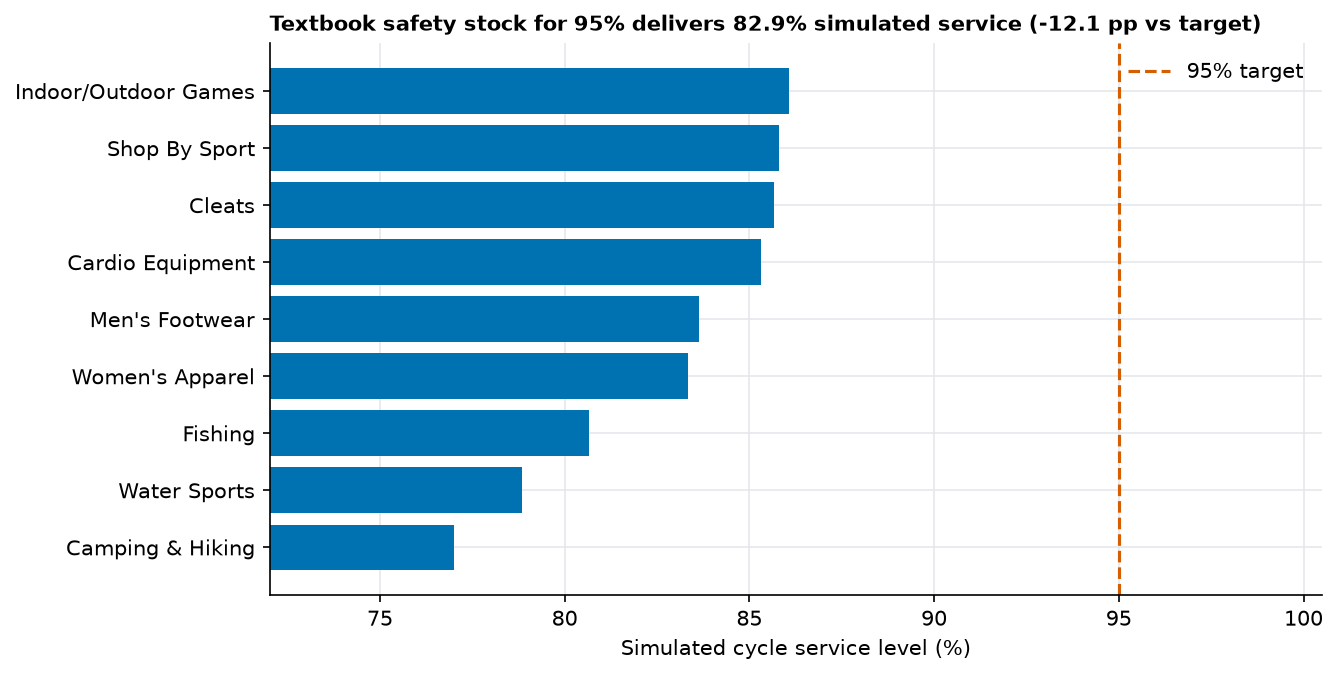

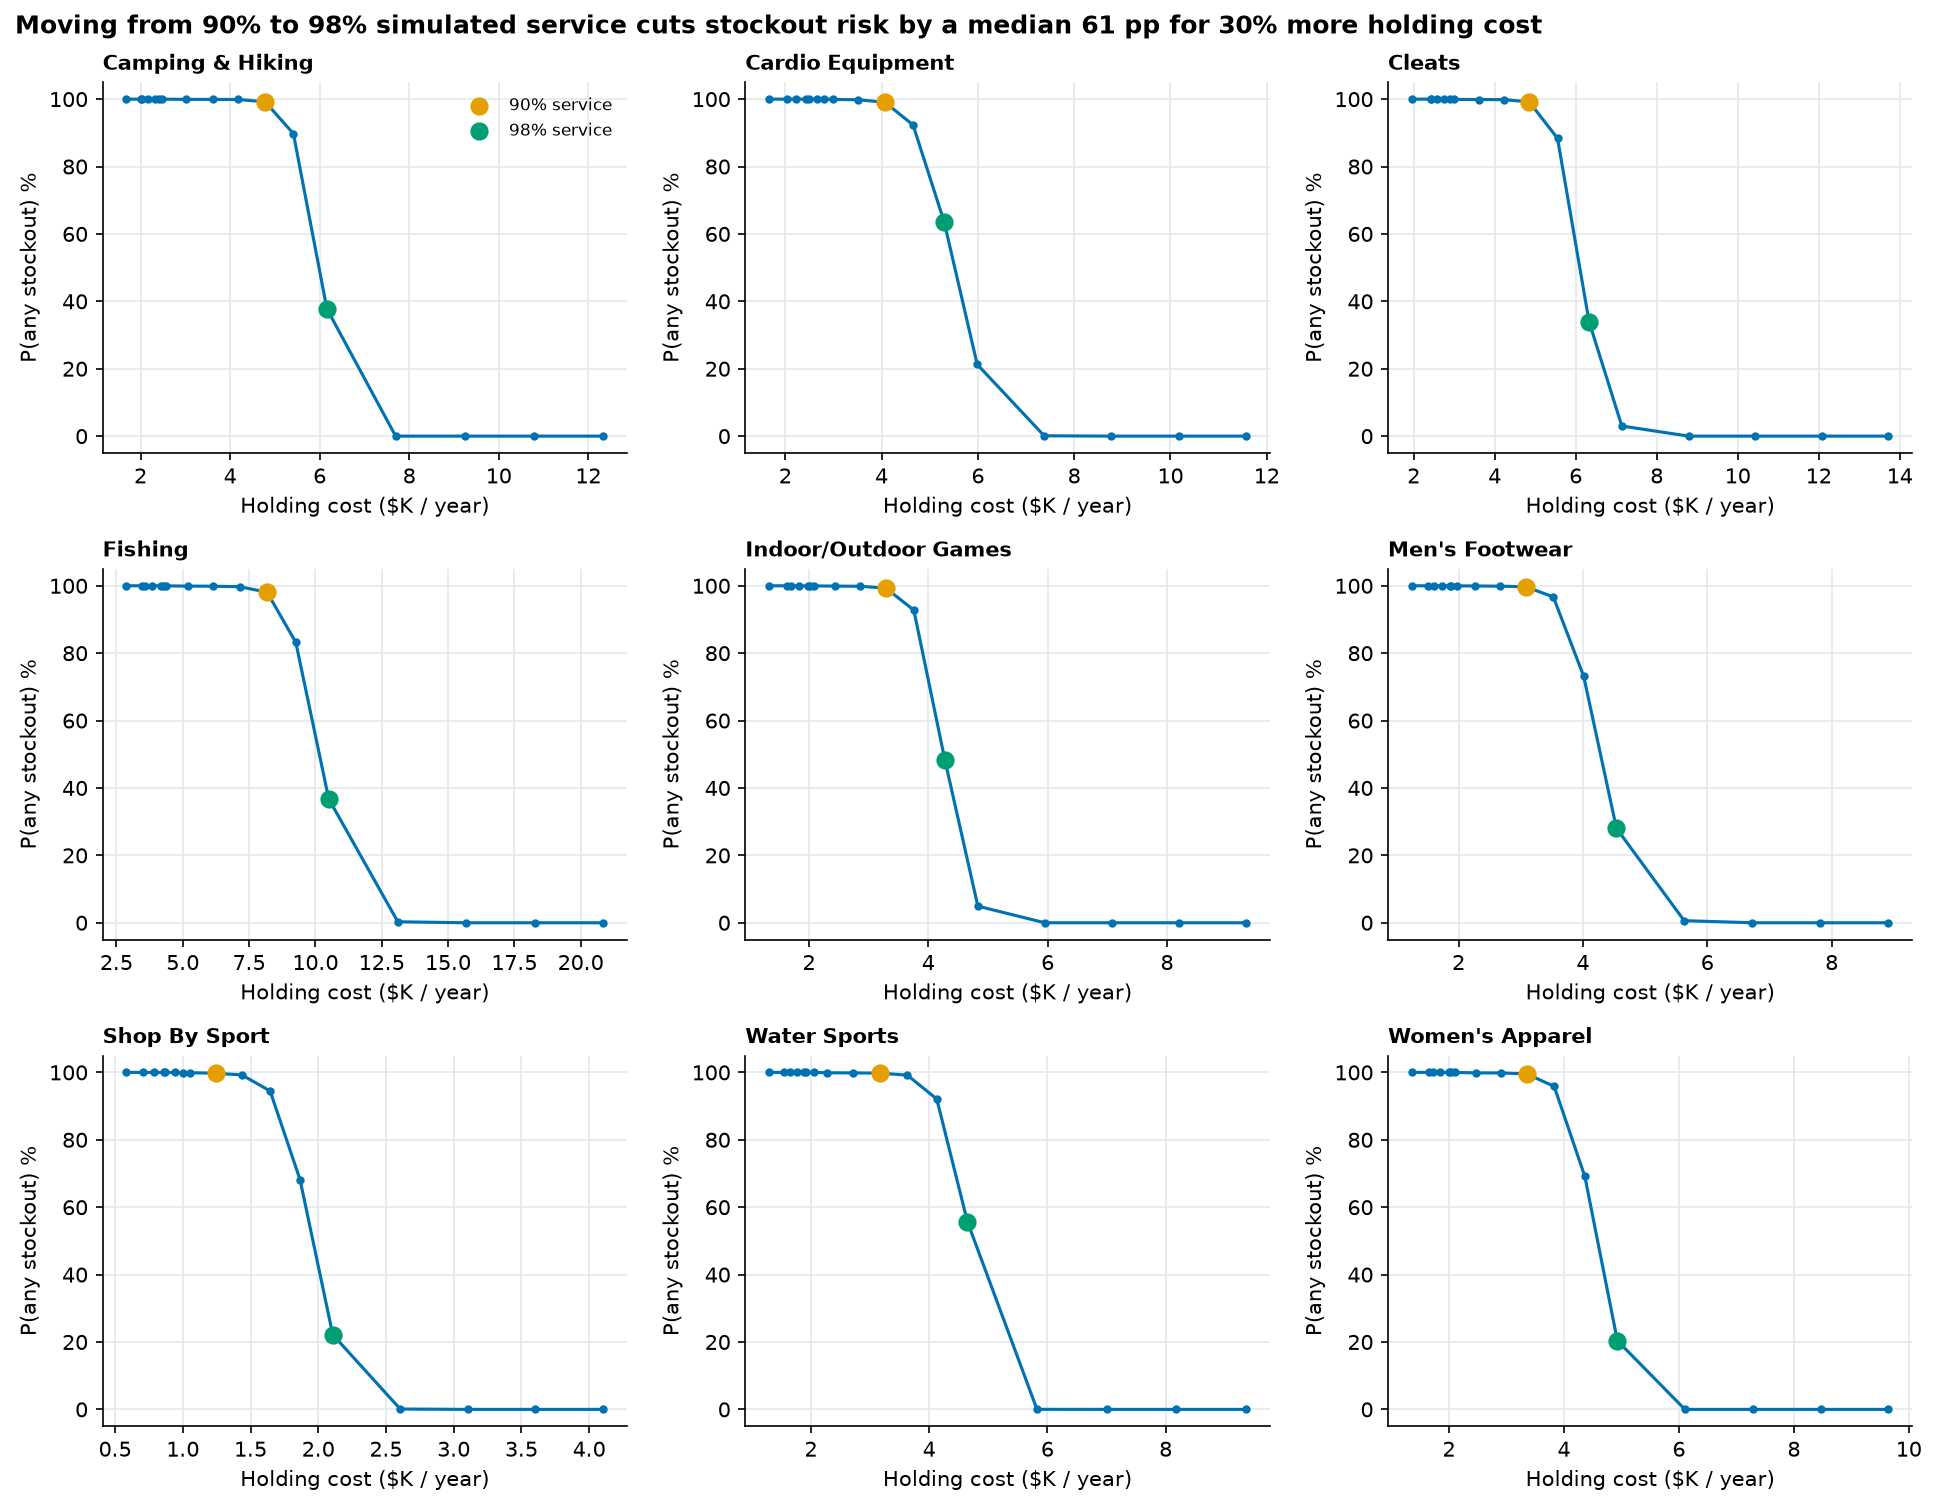

## Recommendations

For each category, the comparison is the cheapest safety stock that reaches a simulated cycle service level of 90% versus the cheapest that reaches 98%.

![Trade-off](figures/simulation_01_tradeoff.png)

- Camping & Hiking: raising safety stock from 99 to 132 units cuts stockout risk (at least one stockout in 52 weeks) from 99% to 38% for 29% more holding cost.
- Cardio Equipment: raising safety stock from 228 to 319 units cuts stockout risk (at least one stockout in 52 weeks) from 99% to 64% for 30% more holding cost.
- Cleats: raising safety stock from 438 to 614 units cuts stockout risk (at least one stockout in 52 weeks) from 99% to 34% for 30% more holding cost.
- Fishing: raising safety stock from 125 to 166 units cuts stockout risk (at least one stockout in 52 weeks) from 98% to 37% for 28% more holding cost.
- Indoor/Outdoor Games: raising safety stock from 360 to 504 units cuts stockout risk (at least one stockout in 52 weeks) from 99% to 48% for 30% more holding cost.
- Men's Footwear: raising safety stock from 135 to 216 units cuts stockout risk (at least one stockout in 52 weeks) from 100% to 28% for 47% more holding cost.
- Shop By Sport: raising safety stock from 160 to 319 units cuts stockout risk (at least one stockout in 52 weeks) from 100% to 22% for 70% more holding cost.
- Water Sports: raising safety stock from 94 to 150 units cuts stockout risk (at least one stockout in 52 weeks) from 100% to 56% for 47% more holding cost.
- Women's Apparel: raising safety stock from 378 to 604 units cuts stockout risk (at least one stockout in 52 weeks) from 100% to 20% for 47% more holding cost.

| Category | From (units) | To (units) | Stockout risk before | Stockout risk after | Holding cost increase |
|---|---|---|---|---|---|
| Camping & Hiking | 99 | 132 | 99% | 38% | +29% |
| Cardio Equipment | 228 | 319 | 99% | 64% | +30% |
| Cleats | 438 | 614 | 99% | 34% | +30% |
| Fishing | 125 | 166 | 98% | 37% | +28% |
| Indoor/Outdoor Games | 360 | 504 | 99% | 48% | +30% |
| Men's Footwear | 135 | 216 | 100% | 28% | +47% |
| Shop By Sport | 160 | 319 | 100% | 22% | +70% |
| Water Sports | 94 | 150 | 100% | 56% | +47% |
| Women's Apparel | 378 | 604 | 100% | 20% | +47% |

Across the 9 categories the annual holding cost goes from $36,011 to $48,792 (+35%) under these assumptions.



In [5]:
report = (paths.reports_dir / "simulation_results.md").read_text(encoding="utf-8")
display(Markdown("## Analytic baseline vs simulation" + report.split("## Analytic baseline vs simulation")[1].split("## Trade-off")[0]))
display(Image(paths.figures_dir / "simulation_02_analytic_vs_simulated.png"))
display(Image(paths.figures_dir / "simulation_01_tradeoff.png"))
display(Markdown("## Recommendations" + report.split("## Trade-off and recommendations")[1].split("## Caveats")[0]))